# 06 — Os dois classificadores: CNN e RNN

Os dois classificadores do projeto (o enunciado pede dois de entre MLP, CNN e RNN):

- **CNN 2D** (`src/cnn.py`): procura padrões **locais** no mel-espectrograma de cada janela de 4 s.
- **RNN** (`src/rnn.py`): lê a mesma janela como uma **sequência** de 401 frames de 10 ms (cada um com 40 bandas
  mel), com uma GRU bidirecional.

As duas redes recebem **exatamente a mesma entrada** e são treinadas e avaliadas **da mesma forma** (mesmos folds,
pesos de classe, aumento de dados, agregação por paciente e limiares encadeados). Por isso a comparação mede só
"padrões locais" contra "modelo de sequência". A MLP foi a primeira abordagem e foi substituída pela RNN
(`03_mlp.ipynb`).

Este notebook reúne:
1. a arquitetura da RNN;
2. o **diário de iterações** dos dois modelos: o que mudámos, porquê e o que aconteceu;
3. as curvas de treino;
4. a comparação final CNN vs RNN;
5. para onde olha a RNN com atenção (comparação com as segmentações do ciclo cardíaco);
6. a comparação com os outros modelos (MLP e HearHeart, o vencedor do Challenge);
7. as conclusões e o teste final (só no fim).

Todos os modelos foram treinados no Deucalion (`scripts/deucalion_cnn.sbatch`, `scripts/deucalion_rnn.sbatch`) e
trazidos com `bash scripts/fetch_deucalion.sh <nome>`. Este notebook só carrega os resultados.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score
from src.data import CLASSES, STATES, load_segmentation
from src.datasets import load_processed, CNNWindows
from src.evaluate import RESULTS_DIR, result_dir, patient_scores, cv_report, tune_thresholds, predict_rule, confusion_df, load_oof
from src.metrics import report
pd.set_option('display.width', 160)
d = load_processed()

## 1. A RNN

A janela 40 × 401 é transposta para uma sequência de **401 passos**, cada um com as **40 bandas mel** desse
instante. Uma **GRU** (*gated recurrent unit*) lê os passos por ordem e mantém um estado escondido que resume o que
já viu; as "portas" decidem o que guardar e o que esquecer, o que evita que a memória se perca ao fim de poucos
passos (como numa RNN simples). Sendo **bidirecional**, há uma GRU a ler para a frente e outra para trás: em cada
instante a rede sabe o que veio antes *e* o que vem depois, ou seja, em que fase do ciclo cardíaco está.

- 2 camadas GRU, 64 unidades por direção, dropout 0.3 entre camadas;
- as 401 saídas (128 valores cada) são resumidas num vetor por **média** ao longo do tempo (iteração 1) ou por
  **atenção** (iteração 2: uma camada dá uma pontuação a cada frame e a média passa a ser ponderada);
- dropout 0.3 → camada linear → 3 classes.

O tamanho foi escolhido para ter quase os mesmos parâmetros que a CNN, para a comparação ser justa também aí.

In [2]:
from src.rnn import DEFAULT_RNN_CFG, build_model, n_params
from src.cnn import HeartMurmurCNN
rnn_m, cnn_m = build_model(DEFAULT_RNN_CFG), HeartMurmurCNN()
x = torch.zeros(2, 1, 40, 401)
print('entrada:', tuple(x.shape), '-> sequência', tuple(x[:, 0].transpose(1, 2).shape),
      '-> saídas GRU', tuple(rnn_m.rnn(x[:, 0].transpose(1, 2))[0].shape), '-> logits', tuple(rnn_m(x).shape))
print(f'parâmetros: RNN {n_params(rnn_m):,} | CNN {n_params(cnn_m):,}')

entrada: (2, 1, 40, 401) -> sequência (2, 401, 40) -> saídas GRU (2, 401, 128) -> logits (2, 3)
parâmetros: RNN 115,587 | CNN 106,083


## 2. Diário de iterações

Cada iteração parte de uma observação (EDA, curvas de treino ou literatura) e foi treinada nos mesmos 5 folds.
**Regra definida antes de ver os resultados:** uma alteração só fica se aumentar a WA média em mais de 0.02
(cerca de um desvio padrão entre folds) e ganhar de forma consistente nos folds; caso contrário fica a versão
mais simples.

| Iteração | Pasta | O que muda | Porquê |
|---|---|---|---|
| CNN base | `cnn` | — | 4 blocos conv stride 2, GAP; Adam 1e-3, lr constante, early stopping na perda |
| CNN + plateau | `cnn_plateau` | lr ÷ 10 após 3 épocas sem melhorar a perda | curvas de validação ruidosas; no HearHeart a descida da lr foi decisiva |
| CNN + WA | `cnn_wa` | early stopping pela WA por paciente | a perda por janela não está alinhada com a métrica por paciente |
| CNN + plateau + WA | `cnn_plateau_wa` | as duas | para ver se os efeitos se somam |
| RNN base | `rnn` | BiGRU, média no tempo | modelo de sequência com a mesma entrada e treino da CNN |
| RNN + atenção | `rnn_att` | atenção em vez da média | deixar a rede focar os frames com sopro (sístole) |
| RNN + plateau | `rnn_plateau` | como na CNN | idem |
| RNN + WA | `rnn_wa` | como na CNN | idem |
| RNN + plateau + WA | `rnn_plateau_wa` | como na CNN | idem |

In [3]:
ITER = {
    'cnn': ('CNN', 'base'), 'cnn_plateau': ('CNN', '+ plateau'), 'cnn_wa': ('CNN', '+ WA'),
    'cnn_plateau_wa': ('CNN', '+ plateau + WA'),
    'rnn': ('RNN', 'base'), 'rnn_att': ('RNN', '+ atenção'), 'rnn_plateau': ('RNN', '+ plateau'),
    'rnn_wa': ('RNN', '+ WA'), 'rnn_plateau_wa': ('RNN', '+ plateau + WA'),
}


def load(folder):
    idx, oof = load_oof(folder)
    dev = d.windows.loc[idx]
    pat = patient_scores(dev, oof)
    table, pred, rep = cv_report(pat)
    cfg = json.loads((result_dir(folder) / 'cv_summary.json').read_text())['cfg']
    hist = {k: pd.read_csv(result_dir(folder) / f'history_fold{k}.csv') for k in range(5)
            if (result_dir(folder) / f'history_fold{k}.csv').exists()}
    return dict(dev=dev, oof=oof, pat=pat, table=table, rep=rep, cfg=cfg, hist=hist)


R = {f: load(f) for f in ITER}
wa = pd.DataFrame({f: R[f]['table']['WA (tuned)'] for f in ITER})


def best_ep(h, cfg):
    return int(h.val_wa.idxmax()) if cfg.get('monitor', 'loss') == 'wa' else int(h.val_loss.idxmin())


rows = []
for f, (model, it) in ITER.items():
    base = 'cnn' if model == 'CNN' else 'rnn'
    delta = wa[f] - wa[base]
    gain = wa[f].mean() - wa[base].mean()
    rows.append({'modelo': model, 'iteração': it, 'WA média': wa[f].mean(), 'WA dp': wa[f].std(),
                 'Δ vs base': gain, 'folds a ganhar': f"{int((delta > 0).sum())}/5" if f != base else '—',
                 **{f'recall {c}': R[f]['rep']['recall'][c] for c in CLASSES},
                 'melhor época (média)': np.mean([best_ep(h, R[f]['cfg']) + 1 for h in R[f]['hist'].values()]),
                 'decisão': 'referência' if f == base else ('adotar' if gain > 0.02 and (delta > 0).sum() >= 4 else 'rejeitar')})
diary = pd.DataFrame(rows).set_index(['modelo', 'iteração'])
diary.round(3)

WA média  WA dp  Δ vs base folds a ganhar  recall Present  recall Unknown  recall Absent  melhor época (média)     decisão
modelo iteração                                                                                                                                  
CNN    base               0.767  0.021      0.000              —           0.783           0.333          0.872                  12.2  referência
       + plateau          0.756  0.017     -0.011            1/5           0.797           0.222          0.858                  11.6    rejeitar
       + WA               0.752  0.034     -0.015            1/5           0.790           0.241          0.851                  14.0    rejeitar
       + plateau + WA     0.773  0.031      0.006            2/5           0.839           0.185          0.858                  14.6    rejeitar
RNN    base               0.761  0.037      0.000              —           0.783           0.241          0.885                   6.8  referência
       + atenção          0.762  0.046      0.000            2/5           0.818           0.167          0.862                   7.0    rejeitar
       + plateau          0.766  0.046      0.005            1/5           0.776           0.259          0.901                   6.4    rejeitar
       + WA               0.753  0.075     -0.008            2/5           0.811           0.185          0.844                   8.0    rejeitar
       + plateau + WA     0.750  0.061     -0.012            2/5           0.783           0.222          0.860                   7.2    rejeitar

In [4]:
print('WA por fold:'); display(wa.round(3))
print('Diferença para a base do mesmo modelo, por fold:')
display(pd.DataFrame({f: wa[f] - wa['cnn' if f.startswith('cnn') else 'rnn'] for f in ITER
                      if f not in ('cnn', 'rnn')}).round(3))

WA por fold:


,cnn,cnn_plateau,cnn_wa,cnn_plateau_wa,rnn,rnn_att,rnn_plateau,rnn_wa,rnn_plateau_wa
fold,,,,,,,,,
0,0.734,0.734,0.696,0.723,0.713,0.709,0.706,0.626,0.651
1,0.758,0.772,0.782,0.807,0.733,0.726,0.733,0.751,0.740
2,0.778,0.768,0.764,0.785,0.778,0.806,0.817,0.813,0.810
3,0.782,0.765,0.744,0.782,0.782,0.754,0.782,0.779,0.775
4,0.783,0.741,0.773,0.766,0.801,0.811,0.794,0.797,0.773


Diferença para a base do mesmo modelo, por fold:


,cnn_plateau,cnn_wa,cnn_plateau_wa,rnn_att,rnn_plateau,rnn_wa,rnn_plateau_wa
fold,,,,,,,
0,0.000,-0.038,-0.010,-0.003,-0.007,-0.087,-0.062
1,0.014,0.025,0.049,-0.007,0.000,0.018,0.007
2,-0.011,-0.014,0.007,0.028,0.039,0.035,0.032
3,-0.017,-0.038,0.000,-0.028,0.000,-0.003,-0.007
4,-0.042,-0.010,-0.017,0.010,-0.007,-0.003,-0.028


## 3. Curvas de treino

Para cada iteração: perda de validação, WA por paciente da validação (afinada no próprio fold, por isso otimista)
e learning rate, ao longo das épocas, com os 5 folds sobrepostos. O círculo marca a época cujos pesos ficaram.
Os runs de referência (`cnn`, `rnn`, `rnn_att`) são anteriores ao registo da WA e da lr por época.

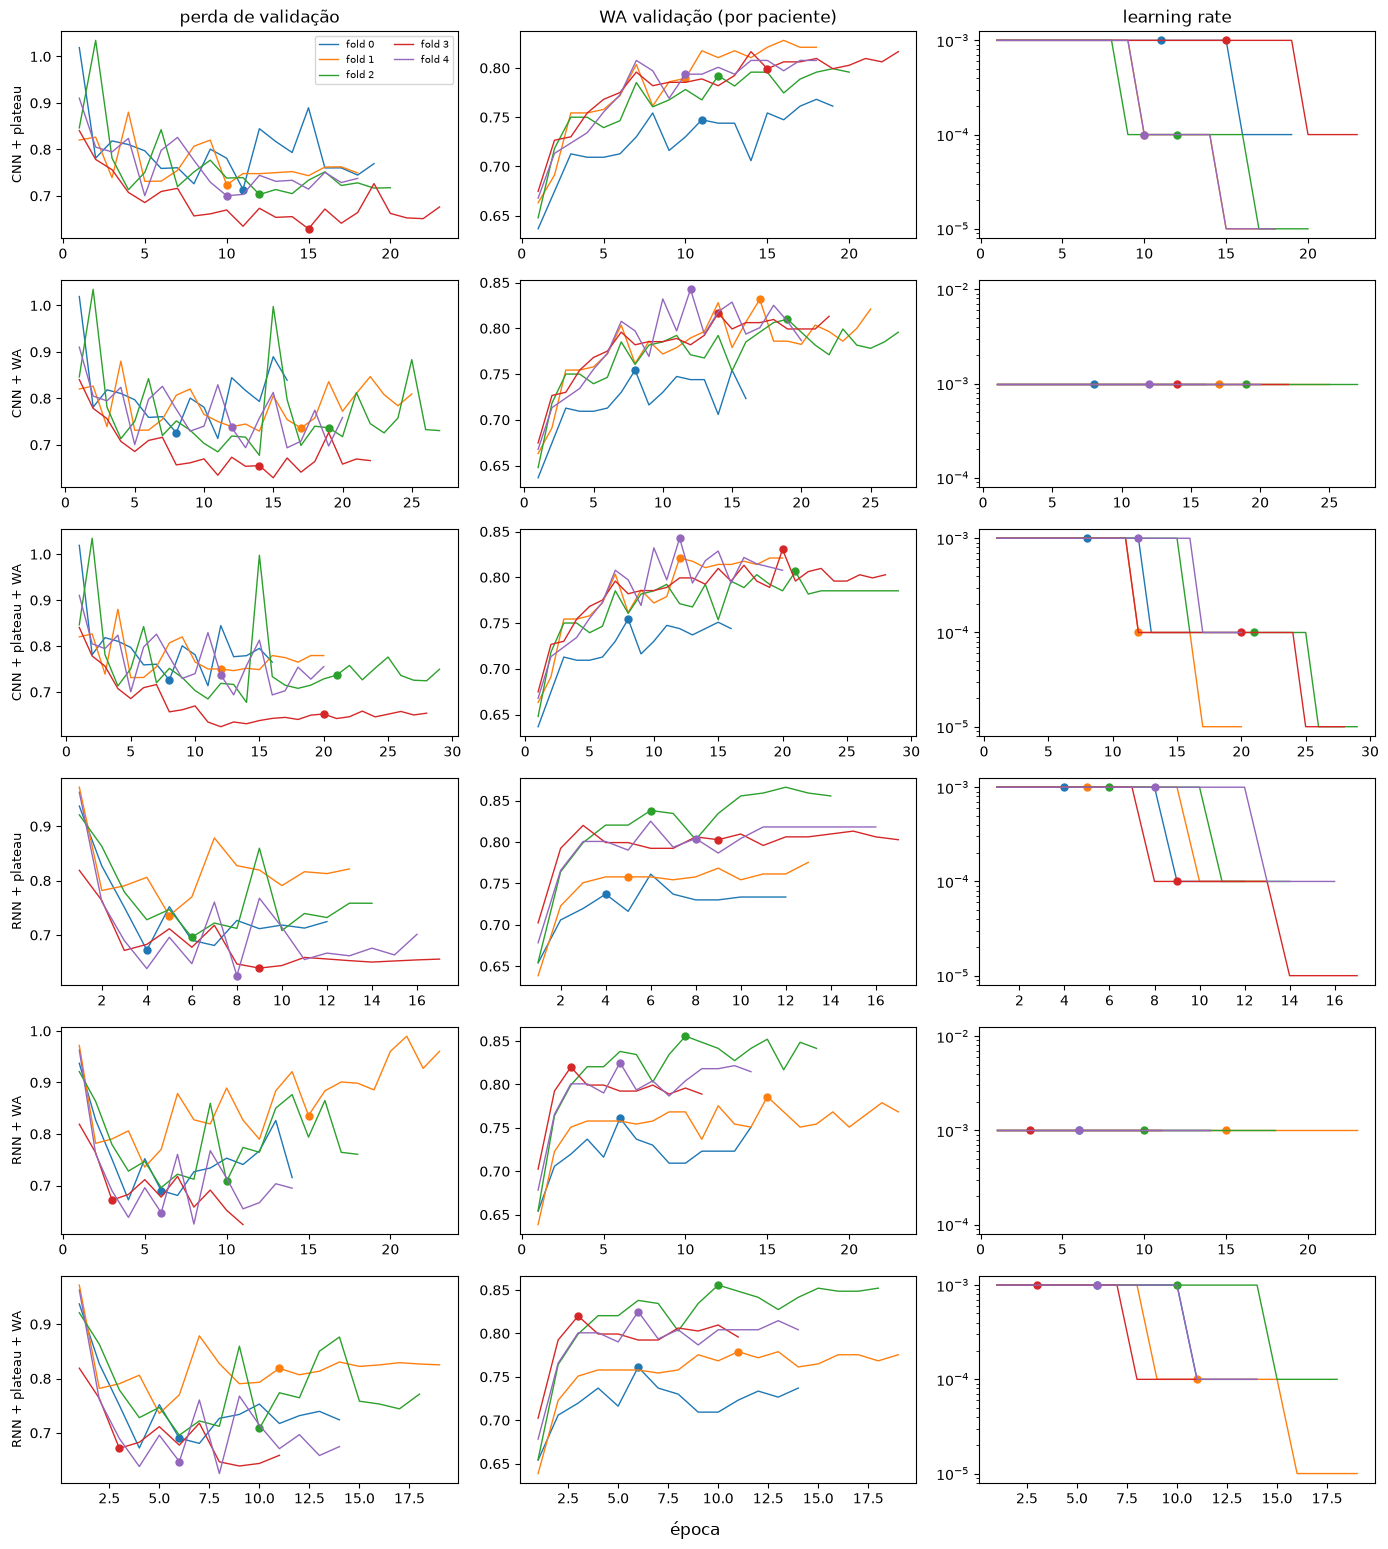

In [5]:
show = ['cnn_plateau', 'cnn_wa', 'cnn_plateau_wa', 'rnn_plateau', 'rnn_wa', 'rnn_plateau_wa']
fig, axes = plt.subplots(len(show), 3, figsize=(14, 2.6 * len(show)), squeeze=False)
for i, f in enumerate(show):
    for k, h in R[f]['hist'].items():
        b = best_ep(h, R[f]['cfg']); e = h.epoch + 1
        for j, col in enumerate(['val_loss', 'val_wa', 'lr']):
            axes[i, j].plot(e, h[col], lw=1, color=f'C{k}', label=f'fold {k}')
            axes[i, j].plot(b + 1, h[col][b], 'o', color=f'C{k}', ms=5)
    axes[i, 0].set_ylabel(f'{ITER[f][0]} {ITER[f][1]}', fontsize=9)
    axes[i, 2].set_yscale('log')
for j, t in enumerate(['perda de validação', 'WA validação (por paciente)', 'learning rate']):
    axes[0, j].set_title(t)
axes[0, 0].legend(fontsize=7, ncol=2); fig.supxlabel('época'); plt.tight_layout()

**Leitura.**
- **Plateau na RNN:** a lr desce *depois* da melhor época (melhor época 4–9, descidas por volta da 8–12) e a perda
  de validação não volta a melhorar: a RNN já convergiu quando a descida acontece, por isso a melhor época quase não
  muda e a WA fica igual.
- **Plateau na CNN:** em alguns folds (2 e 4) a lr desce por volta da época 9 e a melhor época vem logo a seguir, ou
  seja, a descida ainda ajuda a perda de validação. Mas isso não se traduz em melhor WA por paciente (−0.011 em média,
  só 1 fold a ganhar).
- **WA como critério:** a WA por paciente oscila ±0.03–0.05 de época para época (cada fold tem ~150 pacientes e só ~11
  *Unknown*). Escolher o máximo de uma curva tão ruidosa favorece a época com mais sorte nesse fold, o que aumenta a
  variância entre folds (RNN: dp 0.037 → 0.075) em vez de melhorar a WA.

## 4. CNN vs RNN (versões finais)

Pela regra, nenhuma iteração foi adotada: os modelos finais são as versões base, `cnn` e `rnn`.

,parâmetros,WA média,WA dp,WA pooled,recall Present,recall Unknown,recall Absent,AUC Present,AUC Unknown
CNN,106083.0,0.767,0.021,0.767,0.783,0.333,0.872,0.898,0.780
RNN,115587.0,0.761,0.037,0.761,0.783,0.241,0.885,0.923,0.775


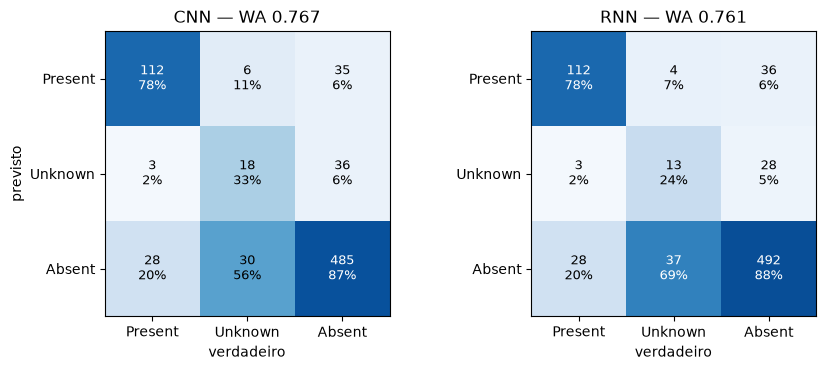

In [6]:
FINAL = {'CNN': 'cnn', 'RNN': 'rnn'}
comp = {}
for n, f in FINAL.items():
    pat, rep, t = R[f]['pat'], R[f]['rep'], R[f]['table']
    y = pat.murmur
    comp[n] = {'parâmetros': n_params(cnn_m) if n == 'CNN' else n_params(rnn_m),
               'WA média': t['WA (tuned)'].mean(), 'WA dp': t['WA (tuned)'].std(), 'WA pooled': rep['weighted_accuracy'],
               **{f'recall {c}': rep['recall'][c] for c in CLASSES},
               'AUC Present': roc_auc_score(y == 'Present', pat.Present), 'AUC Unknown': roc_auc_score(y == 'Unknown', pat.Unknown)}
display(pd.DataFrame(comp).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (n, f) in zip(axes, FINAL.items()):
    m = R[f]['rep']['confusion']; rec = m / m.sum(0, keepdims=True)
    ax.imshow(rec, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{m[i, j]}\n{rec[i, j]:.0%}', ha='center', va='center', color='white' if rec[i, j] > .6 else 'black', fontsize=9)
    ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='verdadeiro',
           title=f"{n} — WA {R[f]['rep']['weighted_accuracy']:.3f}")
axes[0].set_ylabel('previsto'); plt.tight_layout()

**Leitura.** As duas redes ficam empatadas na WA. A RNN distingue melhor os sopros (AUC *Present* mais alta) e a
CNN reconhece melhor o *Unknown*. Modelar a sequência inteira não acrescenta à CNN: cada neurónio da última camada
da CNN já vê ~310 ms, o suficiente para S1 + sístole + S2, e o sopro é um padrão local dessa zona.

## 5. Para onde olha a RNN com atenção?

Usamos as segmentações manuais (`.tsv`: S1, sístole, S2, diástole) **só para interpretar** o modelo (não entram no
treino). Para janelas de validação bem anotadas, comparamos a fração da atenção que cai em cada fase com a fração
de tempo dessa fase (*lift* = atenção / tempo; > 1 significa que a fase recebe mais atenção do que a sua duração).
Cada janela é analisada com o modelo do fold em que ela foi validação.

In [7]:
from src.rnn import load_runs as load_rnn_runs
att_runs, att_cfg = load_rnn_runs(result_dir('rnn_att'))
rows, examples = [], {}
for r in att_runs:
    w = d.windows[d.windows.fold == r['fold']]
    sel = pd.concat([w[w.rec_label == c].sample(150, random_state=0) for c in ['Present', 'Absent']])
    ds = CNNWindows(d, d.windows.index.isin(sel.index), r['band_stats'])
    m = r['model'].cpu().eval()
    with torch.no_grad():
        X = torch.stack([ds[i][0] for i in range(len(ds))])
        _, att = m(X, return_weights=True)
    att = att[:, :, 0].numpy()
    for i, row in enumerate(ds.rows.itertuples()):
        seg = load_segmentation(row.recording)
        t = row.start_s + np.arange(401) * 0.01
        state = np.zeros(401, int)
        for s in seg.itertuples():
            state[(t >= s.start) & (t < s.end)] = s.state
        if (state == 0).mean() > 0.2:
            continue
        examples.setdefault(row.rec_label, (X[i, 0].numpy(), att[i], state))
        for k in (1, 2, 3, 4):
            if (state == k).any():
                rows.append({'gravação': row.rec_label, 'fase': STATES[k], 'atenção': att[i, state == k].sum(), 'tempo': (state == k).mean()})
lift = pd.DataFrame(rows).groupby(['fase', 'gravação'])[['atenção', 'tempo']].mean()
lift['lift'] = lift['atenção'] / lift['tempo']
lift.unstack('gravação').round(3)

atenção          tempo           lift        
gravação  Absent Present Absent Present Absent Present
fase                                                  
S1         0.580   0.620  0.200   0.205  2.900   3.020
S2         0.219   0.078  0.177   0.178  1.234   0.438
diastole   0.134   0.200  0.381   0.393  0.352   0.510
systole    0.060   0.092  0.228   0.208  0.262   0.441

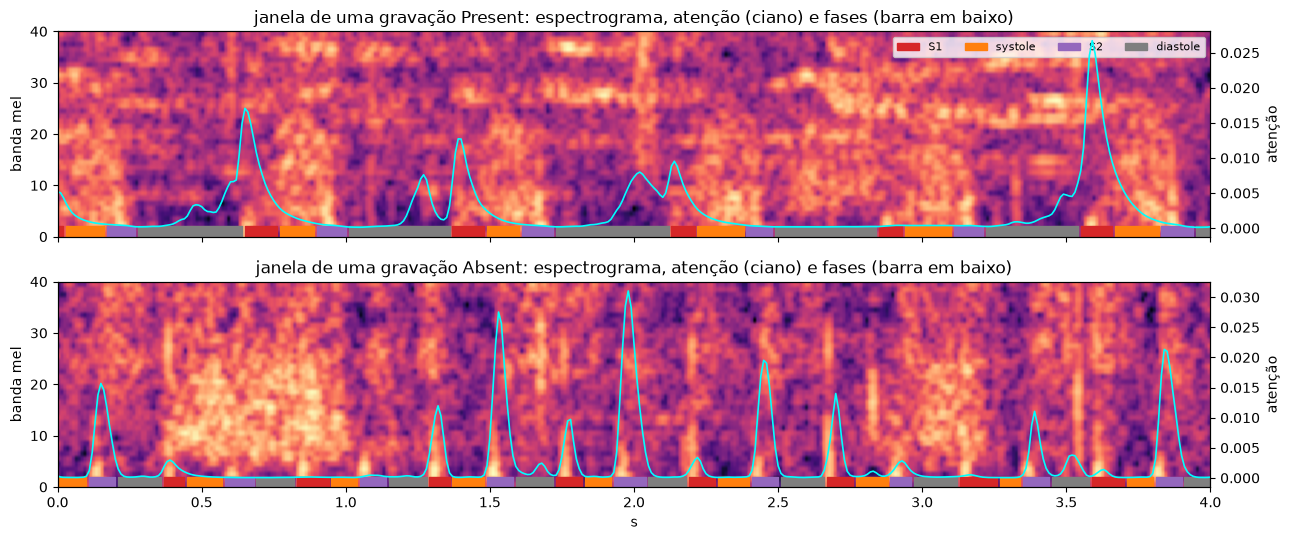

In [8]:
colors = {1: 'tab:red', 2: 'tab:orange', 3: 'tab:purple', 4: 'tab:gray'}
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, lab in zip(axes, ['Present', 'Absent']):
    spec, a, state = examples[lab]
    ax.imshow(spec, origin='lower', aspect='auto', cmap='magma', extent=[0, 4, 0, 40])
    ax2 = ax.twinx(); ax2.plot(np.arange(401) * 0.01, a, color='cyan', lw=1.2); ax2.set_ylabel('atenção')
    for k, c in colors.items():
        ax.fill_between(np.arange(401) * 0.01, 0, 2, where=state == k, color=c, step='mid', label=STATES[k])
    ax.set(ylabel='banda mel', title=f'janela de uma gravação {lab}: espectrograma, atenção (ciano) e fases (barra em baixo)')
axes[0].legend(loc='upper right', fontsize=8, ncol=4); axes[1].set_xlabel('s'); plt.tight_layout()

**Leitura.** A rede ancora-se no **S1**, o som mais forte e regular do ciclo (~3× a atenção que a sua duração
justificaria). Nas gravações **com sopro**, a atenção dada à **sístole** sobe e a do S2 desce: a rede olha mais
para onde está o sopro quando ele existe. Numa GRU bidirecional, o estado no S1 já resume o que vem a seguir
(incluindo a sístole), por isso focar o S1 não significa ignorar a sístole. A atenção não melhorou a WA, mas mostra
que a rede aprendeu algo com sentido clínico.

## 6. Comparação com todos os modelos

Todos avaliados da mesma forma: os mesmos 753 pacientes, os mesmos 5 folds, agregação `max` por paciente e
limiares encadeados. Detalhes do HearHeart em `05_hearheart.ipynb`; resumo de tudo em `reports/report.pdf`.

In [9]:
ALL = {'CNN (classificador 1)': ('cnn', 106_000), 'RNN (classificador 2)': ('rnn', 116_000),
       'MLP (primeira abordagem)': ('mlp', 60_000),
       'HearHeart B (arquitetura)': ('hearheart_arch', 38_000), 'HearHeart A (receita)': ('hearheart', 38_000)}
rows, wa_all = {}, {}
for n, (f, p) in ALL.items():
    x = R[f] if f in R else load(f)
    wa_all[n] = x['table']['WA (tuned)']
    rows[n] = {'parâmetros': f'{p / 1e6:.2f} M' if p >= 1e6 else f'{p / 1e3:.0f} mil',
               'WA média': round(wa_all[n].mean(), 3), 'WA dp': round(wa_all[n].std(), 3),
               'folds a ganhar à CNN': f"{int((wa_all[n] > wa_all['CNN (classificador 1)']).sum())}/5",
               **{f'recall {c}': round(x['rep']['recall'][c], 3) for c in CLASSES}}
pd.DataFrame(rows).T

,parâmetros,WA média,WA dp,folds a ganhar à CNN,recall Present,recall Unknown,recall Absent
CNN (classificador 1),106 mil,0.767,0.021,0/5,0.783,0.333,0.872
RNN (classificador 2),116 mil,0.761,0.037,1/5,0.783,0.241,0.885
MLP (primeira abordagem),60 mil,0.648,0.026,0/5,0.706,0.296,0.676
HearHeart B (arquitetura),38 mil,0.715,0.051,1/5,0.699,0.481,0.802
HearHeart A (receita),38 mil,0.75,0.03,2/5,0.776,0.167,0.885


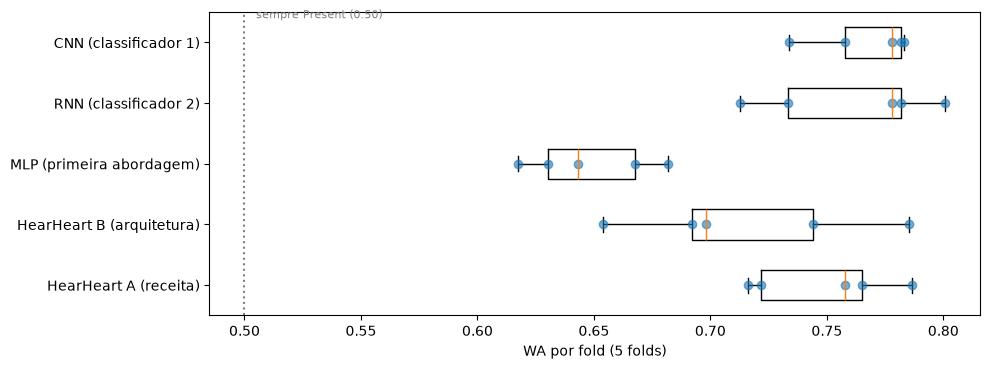

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
order = list(ALL)
ax.boxplot([wa_all[n] for n in order], orientation='horizontal', widths=0.5)
ax.set_yticks(range(1, len(order) + 1), order)
for i, n in enumerate(order, 1):
    ax.plot(wa_all[n], [i] * 5, 'o', alpha=0.6, color='C0')
ax.axvline(0.5, ls=':', c='gray'); ax.text(0.505, 0.6, 'sempre Present (0.50)', fontsize=8, color='gray')
ax.set(xlabel='WA por fold (5 folds)'); ax.invert_yaxis(); plt.tight_layout()

## 7. Conclusões

1. **CNN e RNN empatam** (WA ~0.76–0.77). Modelar a sequência não acrescenta aos padrões locais da CNN. A RNN é
   melhor a distinguir sopros e a CNN a reconhecer *Unknown*.
2. **Nenhuma das iterações de treino passou a regra.** A descida da lr não atua antes de os modelos convergirem; o
   early stopping pela WA é instável porque a WA de um fold é calculada em poucos pacientes. A atenção na RNN não
   melhora a WA, mas mostra que a rede olha mais para a sístole quando há sopro.
3. **Os nossos dois modelos estão ao nível do estado da arte:** a reimplementação do vencedor do Challenge
   (HearHeart), treinada nas mesmas condições, não os ultrapassa.
4. **Limitações:** uma só seed por configuração; sem pesquisa de hiperparâmetros (de propósito, para não
   sobreajustar à validação cruzada); a classe *Unknown* continua difícil para todos os modelos.

**Modelos finais:** `cnn` e `rnn`, com os limiares afinados em todos os folds (abaixo).

In [11]:
T_FINAL = {n: tune_thresholds(R[f]['pat'])[0] for n, f in FINAL.items()}
for n, t in T_FINAL.items():
    print(f'{n}: t_present = {t[0]:.3f}, t_unknown = {t[1]:.3f}')

CNN: t_present = 0.500, t_unknown = 0.725
RNN: t_present = 0.650, t_unknown = 0.700


## 8. Teste — correr só uma vez, no fim

Ensemble dos 5 modelos dos folds sobre os pacientes de teste (fold −1), com os limiares finais. Só depois de todas
as decisões estarem tomadas; o resultado reporta-se tal como sair.

In [12]:
RUN_TEST = True
if RUN_TEST:
    from src.cnn import DEFAULT_CNN_CFG, load_runs as load_cnn_runs, predict_ensemble_cnn
    from src.rnn import predict_ensemble_rnn
    te = (d.windows.fold == -1).to_numpy()
    probs = {'CNN': predict_ensemble_cnn(load_cnn_runs(result_dir('cnn')), d, te, DEFAULT_CNN_CFG | {'num_workers': 0})}
    rnn_runs, rnn_cfg = load_rnn_runs(result_dir('rnn'))
    probs['RNN'] = predict_ensemble_rnn(rnn_runs, d, te, rnn_cfg | {'num_workers': 0})
    for n, p in probs.items():
        pat_te = patient_scores(d.windows[te], p)
        r = report(pat_te.murmur, predict_rule(pat_te, *T_FINAL[n]))
        print(f'{n} — TESTE WA = %.3f' % r['weighted_accuracy'], {c: round(v, 3) for c, v in r['recall'].items()})
        display(confusion_df(r))

CNN — TESTE WA = 0.751 {'Present': np.float64(0.778), 'Unknown': np.float64(0.214), 'Absent': np.float64(0.878)}


,true Present,true Unknown,true Absent
pred Present,28,0,9
pred Unknown,0,3,8
pred Absent,8,11,122


RNN — TESTE WA = 0.789 {'Present': np.float64(0.806), 'Unknown': np.float64(0.357), 'Absent': np.float64(0.899)}


,true Present,true Unknown,true Absent
pred Present,29,0,6
pred Unknown,1,5,8
pred Absent,6,9,125
